# Figure 3

In [1]:
import os
import sys
sys.path.insert(0, "../lib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["pdf.fonttype"] = 42   # keep text editable in Illustrator
plt.rcParams["ps.fonttype"] = 42

from data_io import load_cells, load_traces, load_roi_coordinates
cells = load_cells()
FI = 0.806                    # s per volume
DATASETS = ["P2P3", "P6P7"]
from qc import ACTIVITY_THRESH_DFF
from figure_panels import (cell_counts_by_plane, max_dff_scatter_with_qc_pie, n_subpeaks_vs_max_dff,
                           activity_space_examples)
from correlation_panels import load_animal_group, pairwise_r_distributions
qc = pd.read_parquet("../data/cell_qc.parquet")
feat_df = pd.read_parquet("../data/cell_features.parquet")
coords = load_roi_coordinates()
DATASET = "P6P7"
FIG = "../figures/Fig3"
os.makedirs(FIG, exist_ok=True)
traces = load_traces(DATASET)

## Panel C

plane,1,2,3,4,5,total
Ant #6,25,109,104,44,14,296
Ant #7,15,119,152,99,54,439
Ant #8,65,194,176,73,0,508
Ant #9,48,154,134,80,18,434
Ant #10,78,191,167,103,9,548


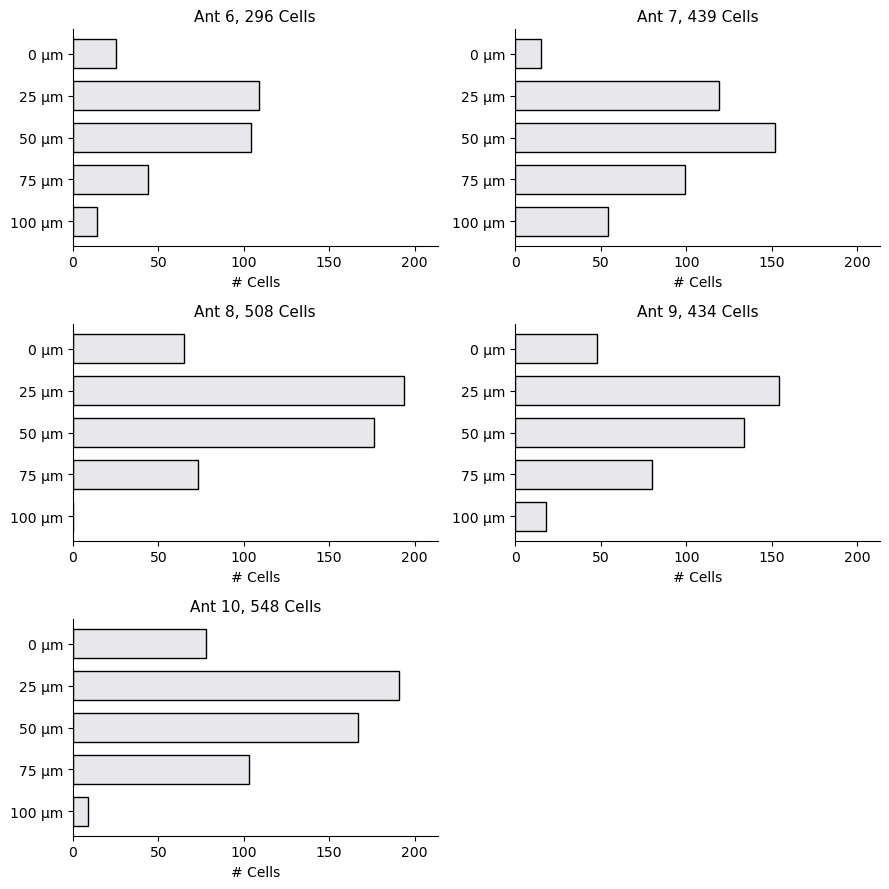

In [2]:
fig, counts = cell_counts_by_plane(cells, DATASET, f"{FIG}/Fig3C_cell_counts_by_plane")
counts.assign(total=counts.sum(axis=1))

## Panel E

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


{'n_included': 2063, 'n_excluded': 162, 'pct_active': 92.71910112359551}

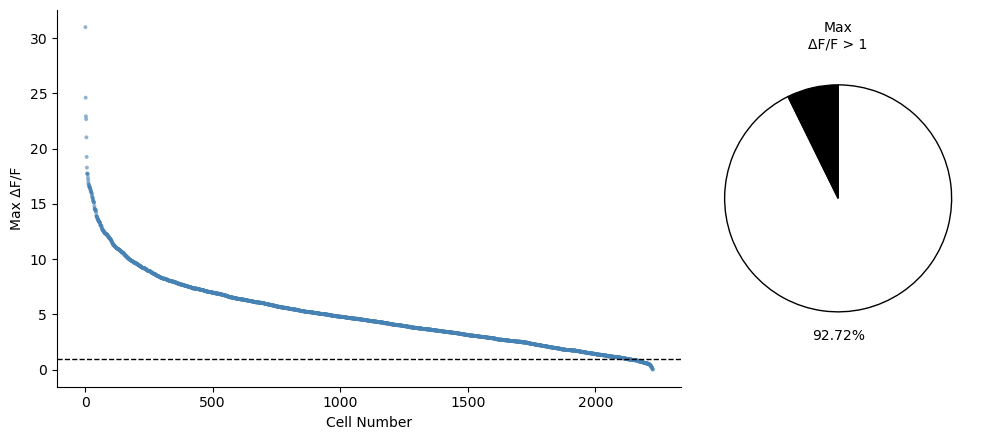

In [3]:
fig, stats = max_dff_scatter_with_qc_pie(qc, DATASET, ACTIVITY_THRESH_DFF, f"{FIG}/Fig3E_max_dff_and_activity_pie",
                                         ylabel="Max ΔF/F")
stats

## Panels F–G

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


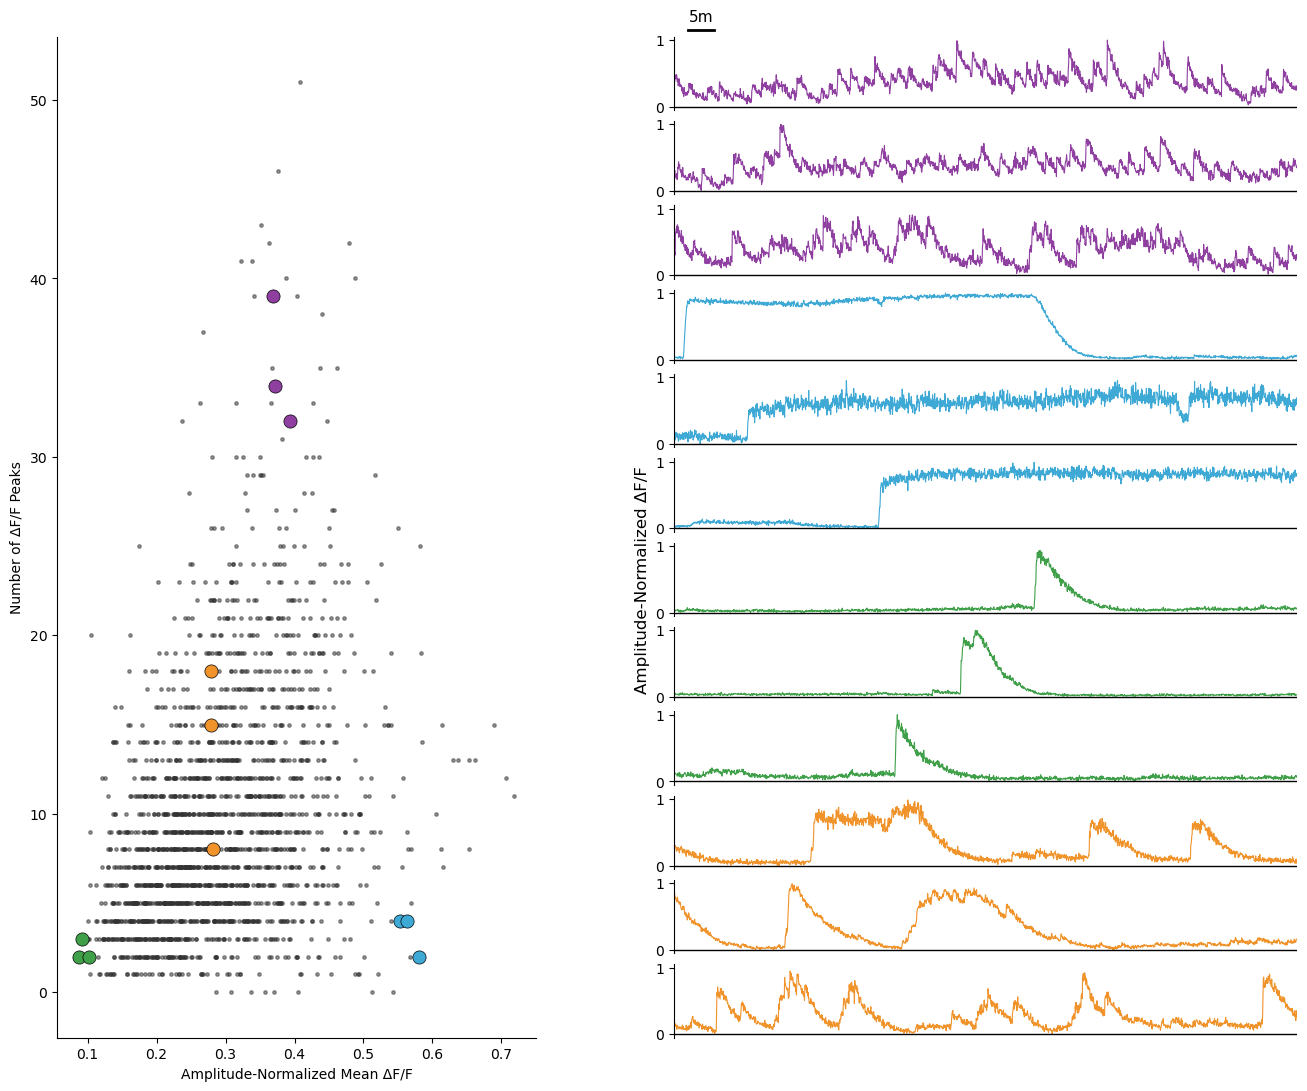

In [4]:
EXAMPLE_CELL_IDS = {'#8e3fa0': [2226, 3041, 3323], '#3fa9d6': [2958, 1301, 3002], '#3fa049': [2015, 2336, 1298], '#f0932b': [2581, 2676, 3023]}
fig = activity_space_examples(feat_df, cells, traces, DATASET, EXAMPLE_CELL_IDS, FI,
                              f"{FIG}/Fig3FG_activity_space_and_example_traces")

## Panels H–I

    ant  n_cells  n_total_pairs  n_artifact_pairs  pct_excluded
 Ant #6      261          33930               405      1.193634
 Ant #7      413          85078               738      0.867439
 Ant #8      482         115921              1058      0.912691
 Ant #9      385          73920               757      1.024080
Ant #10      522         135981              1074      0.789816
total: 4032 of 444830 pairs excluded (0.91%)


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


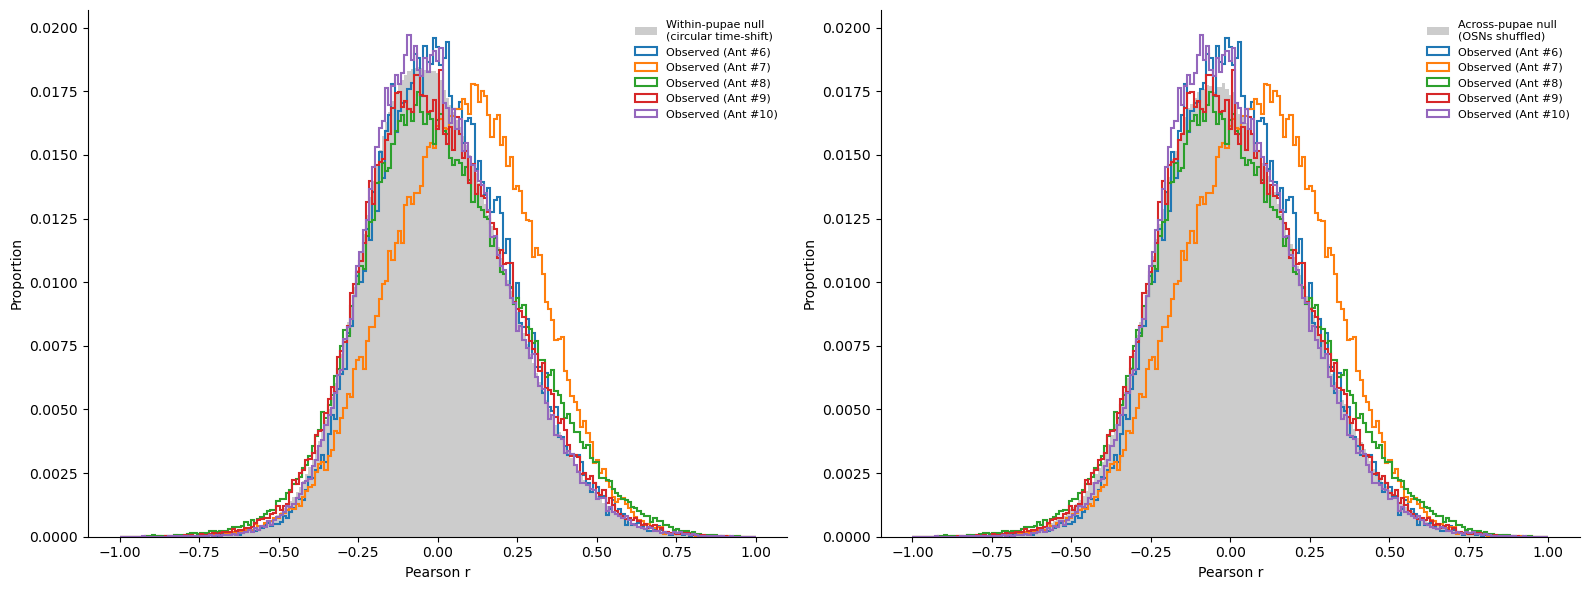

In [5]:
group = load_animal_group(DATASET, cells, qc, coords)
print(group["pairs"].to_string(index=False))
print(f"total: {group['pairs'].n_artifact_pairs.sum()} of {group['pairs'].n_total_pairs.sum()} pairs excluded "
      f"({100 * group['pairs'].n_artifact_pairs.sum() / group['pairs'].n_total_pairs.sum():.2f}%)")
fig = pairwise_r_distributions(group, DATASET, FI, f"{FIG}/Fig3HI_pairwise_r_distributions")

## Figure S2, Panel A

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


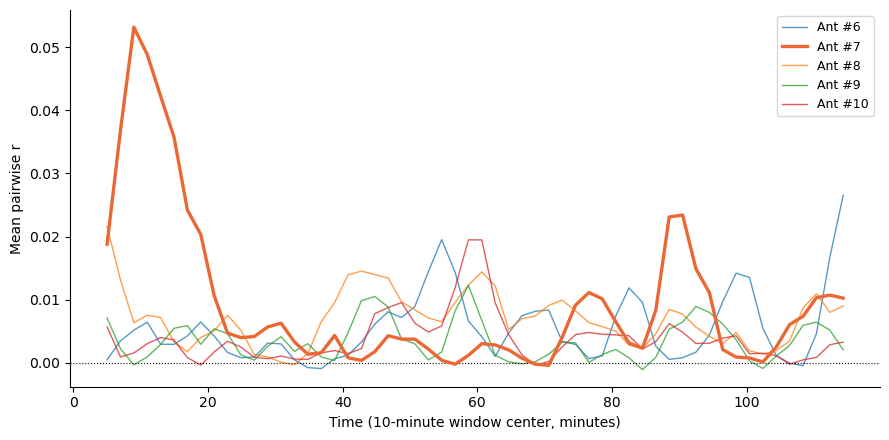

In [6]:
\
from correlation_panels import sliding_mean_r
from features import normalize_trace
ANT = {name: name for name in group["names"]}      # group["names"] are the figure labels (Ant #6-10)
EPOCH = "Ant #7"
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, tr, keep in zip(group["names"], group["traces"], group["keep"]):
    t, mr = sliding_mean_r(tr, keep, FI)
    bold = name == EPOCH
    ax.plot(t, mr, lw=2.4 if bold else 1.0, color="#eb6834" if bold else None, alpha=1.0 if bold else 0.75,
            zorder=3 if bold else 2, label=ANT[name])
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_xlabel("Time (10-minute window center, minutes)"); ax.set_ylabel("Mean pairwise r")
ax.legend(fontsize=9); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/FigS2A_correlation_over_time.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/FigS2A_correlation_over_time.eps", bbox_inches="tight")

## Figure S2, Panel B

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


% of cells active at the first frame: {'Ant #6': 57.1, 'Ant #7': 12.6, 'Ant #8': 63.1, 'Ant #9': 46.5, 'Ant #10': 49.0}


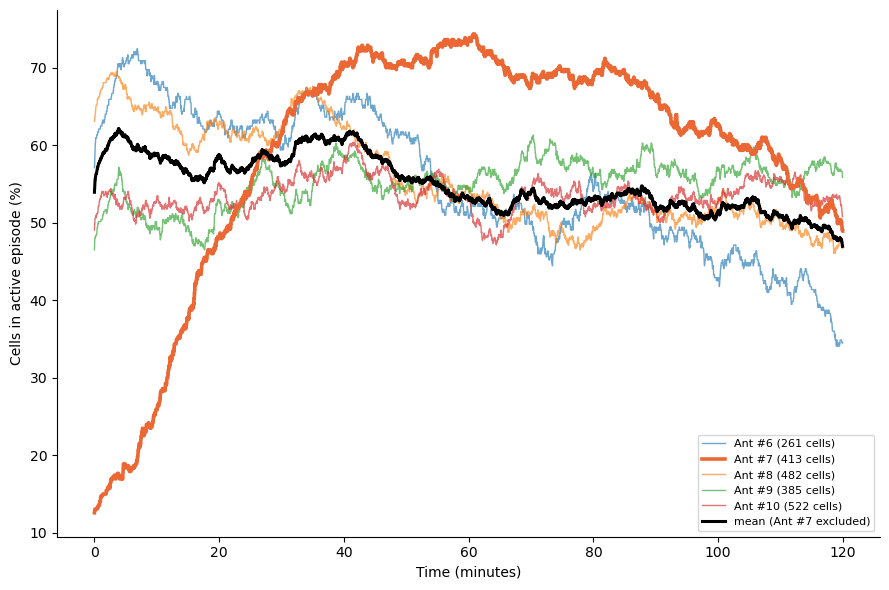

In [7]:
\
ep = pd.read_parquet("../data/episodes.parquet")
ep = ep[ep.dataset == "P6P7"]
fig, ax = plt.subplots(figsize=(9, 6))
occ_other, start_pct = [], {}
for name, tr in zip(group["names"], group["traces"]):
    n_cells, T = tr.shape
    count = np.zeros(T)
    for e in ep[ep.ant == name].itertuples():
        count[e.onset_frame:e.offset_frame + 1] += 1
    occ = 100 * count / n_cells; start_pct[ANT[name]] = round(float(occ[0]), 1)
    t_min = np.arange(T) * FI / 60
    bold = name == EPOCH
    ax.plot(t_min, occ, lw=2.6 if bold else 1.0, color="#eb6834" if bold else None, alpha=1.0 if bold else 0.65,
            zorder=3 if bold else 2, label=f"{ANT[name]} ({n_cells} cells)")
    if not bold:
        occ_other.append(occ)
ax.plot(t_min, np.mean(np.vstack(occ_other), axis=0), color="black", lw=2.2, zorder=4, label=f"mean ({ANT[EPOCH]} excluded)")
ax.set_xlabel("Time (minutes)"); ax.set_ylabel("Cells in active episode (%)")
ax.legend(fontsize=8, loc="lower right"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/FigS2B_episode_occupancy.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/FigS2B_episode_occupancy.eps", bbox_inches="tight")
print("% of cells active at the first frame:", start_pct)

## Figure S2, Panel C

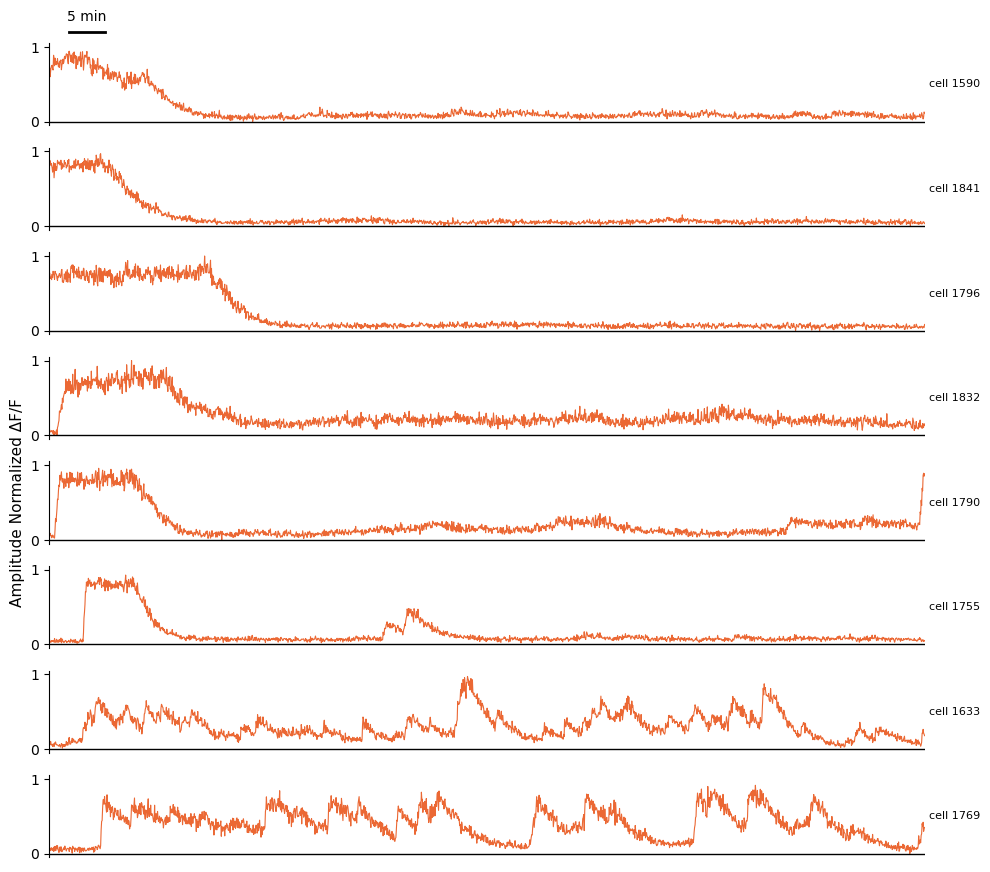

In [8]:
\
EXAMPLE_CELL_IDS = [1590, 1841, 1796, 1832, 1790, 1755, 1633, 1769]
epoch_cells = (cells[(cells.dataset == "P6P7") & (cells.ant == EPOCH)].sort_values("row_in_dataset")
               .merge(qc[["cell_id", "excluded"]], on="cell_id"))
epoch_cells = epoch_cells[~epoch_cells.excluded].reset_index(drop=True)
pos = {cid: i for i, cid in enumerate(epoch_cells.cell_id)}
epoch_traces = group["traces"][group["names"].index(EPOCH)]
DECIM = 5; scale_bar = int(300 / FI)
fig, axes = plt.subplots(len(EXAMPLE_CELL_IDS), 1, figsize=(10, 1.1 * len(EXAMPLE_CELL_IDS)))
for i, (ax, cid) in enumerate(zip(axes, EXAMPLE_CELL_IDS)):
    tr = normalize_trace(epoch_traces[pos[cid]])
    ax.plot(np.arange(len(tr))[::DECIM], tr[::DECIM], color="#eb6834", linewidth=0.8)
    ax.axhline(0, color="black", linewidth=1); ax.set_xlim(0, len(tr) - 1); ax.set_ylim(-0.05, 1.05)
    ax.set_yticks([0, 1]); ax.set_xticks([]); ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.text(1.005, 0.5, f"cell {cid}", transform=ax.transAxes, fontsize=8, va="center")
    if i == 0:
        ax.plot([200, 200 + scale_bar], [1.2, 1.2], color="black", lw=2, clip_on=False)
        ax.text(200 + scale_bar / 2, 1.35, "5 min", ha="center", fontsize=10, clip_on=False)
    if i == len(EXAMPLE_CELL_IDS) // 2:
        ax.set_ylabel("Amplitude Normalized ΔF/F", fontsize=11)
plt.tight_layout()
plt.savefig(f"{FIG}/FigS2C_example_traces.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/FigS2C_example_traces.eps", bbox_inches="tight")